In [ ]:
# Task 38: Classification Accuracy

**Tools:** Python, Pandas, NumPy, Scikit-learn, Matplotlib

## Objective

Calculate the accuracy of a classification model
and compare predicted values with actual target values.

## Deliverables

- Actual and predicted values
- Classification accuracy score
- Accuracy percentage
- Confusion matrix
- Classification report
- Short interpretation of model performance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Breast Cancer Wisconsin Dataset
cancer = load_breast_cancer()

# Extract input features
X_original = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Original Scikit-learn encoding:
# 0 = Malignant
# 1 = Benign

# Convert diagnosis into our required encoding:
# 0 = Benign
# 1 = Malignant

diagnosis = pd.Series(
    cancer.target
).map({
    0: "Malignant",
    1: "Benign"
})

y = pd.Series(
    (cancer.target == 0).astype(int),
    name="target"
)

# Create dataset
df = X_original.copy()

df["diagnosis"] = diagnosis.values
df["target"] = y.values

print("Dataset loaded successfully!")

print("Total records:", len(df))
print("Total features:", X_original.shape[1])

display(df.head())

Dataset loaded successfully!
Total records: 569
Total features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant,1


In [3]:
# Save original dataset
df.to_csv(
    "breast_cancer_dataset.csv",
    index=False
)

# Save prepared dataset
df.to_csv(
    "prepared_classification_dataset.csv",
    index=False
)

print("Dataset files saved successfully!")

Dataset files saved successfully!


In [4]:
print("=" * 50)
print("DATASET DIMENSIONS")
print("=" * 50)

print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Number of input features:", X_original.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

DATASET DIMENSIONS
Number of records: 569
Number of columns: 32
Number of input features: 30

Column names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis', 'target']


In [5]:
print("DATASET INFORMATION")

df.info()

print("\nSTATISTICAL SUMMARY")

display(X_original.describe())

print("\nMISSING VALUES")

print(df.isnull().sum().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smooth

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500



MISSING VALUES
0


In [6]:
# Select input features
X = X_original.copy()

print("INPUT FEATURES (X)")

display(X.head())

print("\nNumber of features:", X.shape[1])

print("Feature dataset shape:", X.shape)

INPUT FEATURES (X)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Number of features: 30
Feature dataset shape: (569, 30)


In [7]:
# Select target variable
y = df["target"].copy()

print("TARGET VARIABLE (y)")

display(y.head(10))

print("\nTarget shape:", y.shape)

print("\nUnique target values:")

print(sorted(y.unique()))

TARGET VARIABLE (y)


,target
0,1
1,1
2,1
3,1
4,1
5,1
6,1
7,1
8,1
9,1



Target shape: (569,)

Unique target values:
[np.int64(0), np.int64(1)]


In [8]:
target_mapping = {
    0: "Benign",
    1: "Malignant"
}

class_counts = y.map(
    target_mapping
).value_counts()

print("TARGET CLASS DISTRIBUTION")

display(class_counts)

print("\nTotal classes:", y.nunique())

TARGET CLASS DISTRIBUTION


,count
target,
Benign,357
Malignant,212



Total classes: 2


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN-TEST SPLIT")

print("\nTraining records:", len(X_train))

print("Testing records:", len(X_test))

print("\nTraining shape:", X_train.shape)

print("Testing shape:", X_test.shape)

TRAIN-TEST SPLIT

Training records: 455
Testing records: 114

Training shape: (455, 30)
Testing shape: (114, 30)


In [10]:
model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

print("Decision Tree Classifier initialized successfully!")

Decision Tree Classifier initialized successfully!


In [11]:
# Train classification model

model.fit(
    X_train,
    y_train
)

print("=" * 50)
print("MODEL TRAINING")
print("=" * 50)

print("Decision Tree training completed successfully!")

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("Input features:", X_train.shape[1])

MODEL TRAINING
Decision Tree training completed successfully!
Training records: 455
Testing records: 114
Input features: 30


In [12]:
# Generate predictions

y_pred = model.predict(X_test)

print("PREDICTION RESULTS")

print("\nFirst 15 predicted values:")

print(y_pred[:15])

print("\nFirst 15 actual values:")

print(y_test.iloc[:15].values)

PREDICTION RESULTS

First 15 predicted values:
[0 1 1 0 0 0 1 0 0 0 1 0 1 0 0]

First 15 actual values:
[0 1 0 1 0 0 1 0 0 0 1 0 1 0 0]


In [13]:
# Create comparison DataFrame

comparison_df = pd.DataFrame({
    "Actual_Values": y_test,
    "Predicted_Values": y_pred
})

comparison_df["Actual_Diagnosis"] = (
    comparison_df["Actual_Values"]
    .map(target_mapping)
)

comparison_df["Predicted_Diagnosis"] = (
    comparison_df["Predicted_Values"]
    .map(target_mapping)
)

comparison_df["Correct_Prediction"] = (
    comparison_df["Actual_Values"]
    == comparison_df["Predicted_Values"]
)

print("ACTUAL VS PREDICTED VALUES")

display(comparison_df.head(20))

ACTUAL VS PREDICTED VALUES


,Actual_Values,Predicted_Values,Actual_Diagnosis,Predicted_Diagnosis,Correct_Prediction
120,0,0,Benign,Benign,True
250,1,1,Malignant,Malignant,True
375,0,1,Benign,Malignant,False
99,1,0,Malignant,Benign,False
455,0,0,Benign,Benign,True
318,0,0,Benign,Benign,True
39,1,1,Malignant,Malignant,True
371,0,0,Benign,Benign,True
98,0,0,Benign,Benign,True
502,0,0,Benign,Benign,True


In [14]:
# Calculate accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

# Convert accuracy into percentage

accuracy_percentage = accuracy * 100

print("=" * 50)
print("CLASSIFICATION ACCURACY")
print("=" * 50)

print("Accuracy Score:", round(accuracy, 4))

print(
    "Accuracy Percentage:",
    round(accuracy_percentage, 2),
    "%"
)

CLASSIFICATION ACCURACY
Accuracy Score: 0.9123
Accuracy Percentage: 91.23 %


In [15]:
correct_predictions = (
    y_test.values == y_pred
).sum()

incorrect_predictions = (
    y_test.values != y_pred
).sum()

total_predictions = len(y_test)

print("PREDICTION ANALYSIS")

print("\nTotal predictions:", total_predictions)

print("Correct predictions:", correct_predictions)

print("Incorrect predictions:", incorrect_predictions)

print(
    "Accuracy:",
    round(accuracy_percentage, 2),
    "%"
)

PREDICTION ANALYSIS

Total predictions: 114
Correct predictions: 104
Incorrect predictions: 10
Accuracy: 91.23 %


In [16]:
precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

print("CLASSIFICATION EVALUATION")

print("Accuracy:", round(accuracy, 4))

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1-score:", round(f1, 4))

CLASSIFICATION EVALUATION
Accuracy: 0.9123
Precision: 0.9444
Recall: 0.8095
F1-score: 0.8718


In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

confusion_df = pd.DataFrame(
    cm,
    index=[
        "Actual_Benign",
        "Actual_Malignant"
    ],
    columns=[
        "Predicted_Benign",
        "Predicted_Malignant"
    ]
)

print("CONFUSION MATRIX")

display(confusion_df)

CONFUSION MATRIX


,Predicted_Benign,Predicted_Malignant
Actual_Benign,70,2
Actual_Malignant,8,34


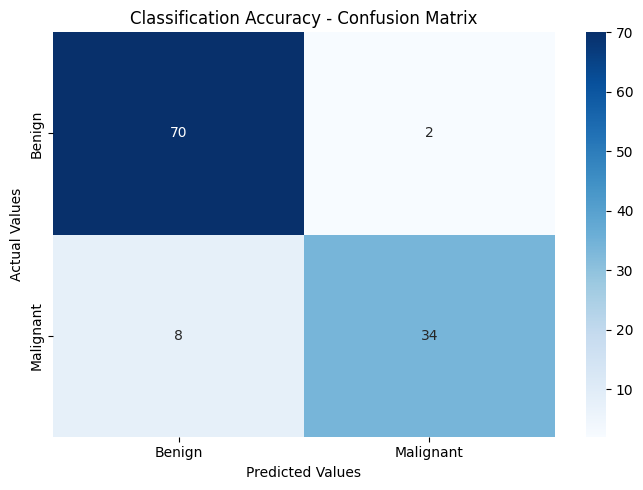

In [18]:
Path("charts").mkdir(
    exist_ok=True
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Classification Accuracy - Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.tight_layout()

plt.savefig(
    "charts/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[
        "Benign",
        "Malignant"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print("CLASSIFICATION REPORT")

display(report_df)

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Benign,0.897436,0.972222,0.933333,72.000000
Malignant,0.944444,0.809524,0.871795,42.000000
accuracy,0.912281,0.912281,0.912281,0.912281
macro avg,0.920940,0.890873,0.902564,114.000000
weighted avg,0.914755,0.912281,0.910661,114.000000


In [20]:
print("=" * 55)
print("MODEL PERFORMANCE INTERPRETATION")
print("=" * 55)

print(
    f"The classification model achieved "
    f"{accuracy_percentage:.2f}% accuracy."
)

print(
    f"It correctly classified "
    f"{correct_predictions} out of "
    f"{total_predictions} test records."
)

print(
    f"It incorrectly classified "
    f"{incorrect_predictions} records."
)

if accuracy_percentage >= 90:
    print("The model achieved high accuracy on this test split.")
elif accuracy_percentage >= 75:
    print("The model achieved moderate accuracy on this test split.")
else:
    print("The model's accuracy indicates scope for improvement.")

print(
    "\nOther metrics such as precision, recall, "
    "and F1-score should also be considered."
)

MODEL PERFORMANCE INTERPRETATION
The classification model achieved 91.23% accuracy.
It correctly classified 104 out of 114 test records.
It incorrectly classified 10 records.
The model achieved high accuracy on this test split.

Other metrics such as precision, recall, and F1-score should also be considered.


In [21]:
# Original dataset

df.to_csv(
    "breast_cancer_dataset.csv",
    index=False
)

# Prepared dataset

df.to_csv(
    "prepared_classification_dataset.csv",
    index=False
)

# Features

X.to_csv(
    "classification_features.csv",
    index=False
)

# Target

target_df = pd.DataFrame({
    "diagnosis": diagnosis,
    "target": y
})

target_df.to_csv(
    "classification_target.csv",
    index=False
)

# Actual and predicted values

comparison_df.to_csv(
    "classification_predictions.csv",
    index=False
)

# Evaluation summary

evaluation_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Accuracy Percentage",
        "Precision",
        "Recall",
        "F1 Score",
        "Correct Predictions",
        "Incorrect Predictions",
        "Total Predictions"
    ],

    "Value": [
        accuracy,
        accuracy_percentage,
        precision,
        recall,
        f1,
        correct_predictions,
        incorrect_predictions,
        total_predictions
    ]
})

evaluation_df.to_csv(
    "evaluation_summary.csv",
    index=False
)

# Classification report

report_df.to_csv(
    "classification_report.csv"
)

# Confusion matrix

confusion_df.to_csv(
    "confusion_matrix.csv"
)

print("All CSV files exported successfully!")

All CSV files exported successfully!


In [22]:
import os

print("PROJECT FILES")

for file in [
    "breast_cancer_dataset.csv",
    "prepared_classification_dataset.csv",
    "classification_features.csv",
    "classification_target.csv",
    "classification_predictions.csv",
    "evaluation_summary.csv",
    "classification_report.csv",
    "confusion_matrix.csv",
    "classification_accuracy_model.joblib",
    "charts/confusion_matrix.png"
]:

    if os.path.exists(file):
        print("[OK]", file)
    else:
        print("[MISSING]", file)

PROJECT FILES
[OK] breast_cancer_dataset.csv
[OK] prepared_classification_dataset.csv
[OK] classification_features.csv
[OK] classification_target.csv
[OK] classification_predictions.csv
[OK] evaluation_summary.csv
[OK] classification_report.csv
[OK] confusion_matrix.csv
[MISSING] classification_accuracy_model.joblib
[OK] charts/confusion_matrix.png


In [23]:
from google.colab import files
files.download("breast_cancer_dataset.csv")
files.download("prepared_classification_dataset.csv")
files.download("classification_features.csv")
files.download("classification_target.csv")
files.download("classification_predictions.csv")
files.download("evaluation_summary.csv")
files.download("classification_report.csv")
files.download("confusion_matrix.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
files.download("charts/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>